# Análisis de ventas y rentabilidad

## 1. Introducción

### Objetivo del proyecto

Analizar los datos de ventas para identificar patrones comerciales,
evaluar la rentabilidad y detectar oportunidades de mejora en el negocio.

### Preguntas de negocio

- ¿Cómo evolucionan las ventas a lo largo del tiempo?
- ¿Qué categorías y productos generan mayores ventas?
- ¿Qué regiones son más rentables?
- ¿Qué relación existe entre los descuentos y los beneficios?
- ¿Qué productos o categorías generan pérdidas?

### Herramientas

- Python
- Pandas
- Matplotlib
- Seaborn
- Google Colab



## 2. Carga de datos

En esta sección importamos las librerías necesarias, conectamos Google Drive y cargamos el archivo de ventas en un DataFrame de Pandas.


In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive



## 3. Exploración inicial

Revisamos las dimensiones del conjunto de datos, los nombres de las columnas y una muestra de los registros para comprender cómo está estructurada la información.


In [7]:

import pandas as pd

ruta = '/content/drive/MyDrive/Machine learning/Sample - Superstore.csv'

df = pd.read_csv(ruta, encoding='latin1')

display(df.head())

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164



## 4. Calidad de los datos

Antes de realizar el análisis, evaluamos la calidad del conjunto de datos. Revisaremos los valores faltantes, los registros duplicados, los tipos de datos y las estadísticas descriptivas de las principales variables numéricas.


In [11]:

# 4.1 Revisar tipos de datos

display(df.dtypes.to_frame(name="Tipo de dato"))

# 4.2 Revisar valores faltantes

faltantes = df.isnull().sum()

resumen_faltantes = pd.DataFrame({
    "Valores faltantes": faltantes,
    "Porcentaje (%)": (faltantes / len(df) * 100).round(2)
})

display(resumen_faltantes[resumen_faltantes["Valores faltantes"] > 0])

# 4.3 Revisar registros duplicados

duplicados = df.duplicated().sum()
print(f"Registros duplicados: {duplicados}")

# 4.4 Estadísticas descriptivas

display(df[["Sales", "Quantity", "Discount", "Profit"]].describe())




,Tipo de dato
Row ID,int64
Order ID,object
Order Date,object
Ship Date,object
Ship Mode,object
Customer ID,object
Customer Name,object
Segment,object
Country,object
City,object


,Valores faltantes,Porcentaje (%)


Registros duplicados: 0


,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000



### 4.5 Hallazgos de calidad de los datos

La revisión inicial del conjunto de datos muestra los siguientes resultados:

- El conjunto contiene 9.994 registros y 21 columnas.
- No se encontraron valores faltantes.
- No se identificaron filas completamente duplicadas.
- Las columnas `Order Date` y `Ship Date` requieren conversión a formato de fecha.
- Las variables `Sales`, `Discount` y `Profit` son numéricas y están disponibles para el análisis.
- La variable `Profit` contiene valores negativos, que representan operaciones con pérdidas y deben conservarse para el análisis de rentabilidad.

Como siguiente paso, se prepararán las fechas para facilitar el análisis temporal.



### 4.6 Conversión de fechas

Convertimos las fechas de pedido y envío a un formato que permita calcular tiempos de entrega y analizar la evolución de las ventas.


In [12]:

# Convertir las columnas a formato fecha

df["Order Date"] = pd.to_datetime(
    df["Order Date"], format="%m/%d/%Y"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], format="%m/%d/%Y"
)

# Verificar los cambios
print("Tipos de datos después de la conversión:")
print(df[["Order Date", "Ship Date"]].dtypes)

display(df[["Order Date", "Ship Date"]].head())


Tipos de datos después de la conversión:
Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


,Order Date,Ship Date
0,2016-11-08,2016-11-11
1,2016-11-08,2016-11-11
2,2016-06-12,2016-06-16
3,2015-10-11,2015-10-18
4,2015-10-11,2015-10-18



## 5. Análisis de ventas y rentabilidad

En esta sección analizaremos la evolución temporal de las ventas y los beneficios para identificar tendencias y diferencias entre los periodos estudiados.

### 5.1 Evolución anual

Agruparemos los registros por año para comparar las ventas totales, los beneficios y el número de pedidos.


In [13]:

# Crear la variable año
df["Year"] = df["Order Date"].dt.year

# Resumir las ventas y la rentabilidad por año
ventas_anuales = (
    df.groupby("Year")
    .agg(
        Ventas_Totales=("Sales", "sum"),
        Beneficio_Total=("Profit", "sum"),
        Pedidos=("Order ID", "nunique"),
        Unidades_Vendidas=("Quantity", "sum")
    )
    .reset_index()
)

# Calcular el margen de beneficio
ventas_anuales["Margen_Beneficio_%"] = (
    ventas_anuales["Beneficio_Total"]
    / ventas_anuales["Ventas_Totales"] * 100
).round(2)

# Mostrar resultados
display(ventas_anuales.round(2))


,Year,Ventas_Totales,Beneficio_Total,Pedidos,Unidades_Vendidas,Margen_Beneficio_%
0,2014,484247.50,49543.97,969,7581,10.23
1,2015,470532.51,61618.60,1038,7979,13.10
2,2016,609205.60,81795.17,1315,9837,13.43
3,2017,733215.26,93439.27,1687,12476,12.74


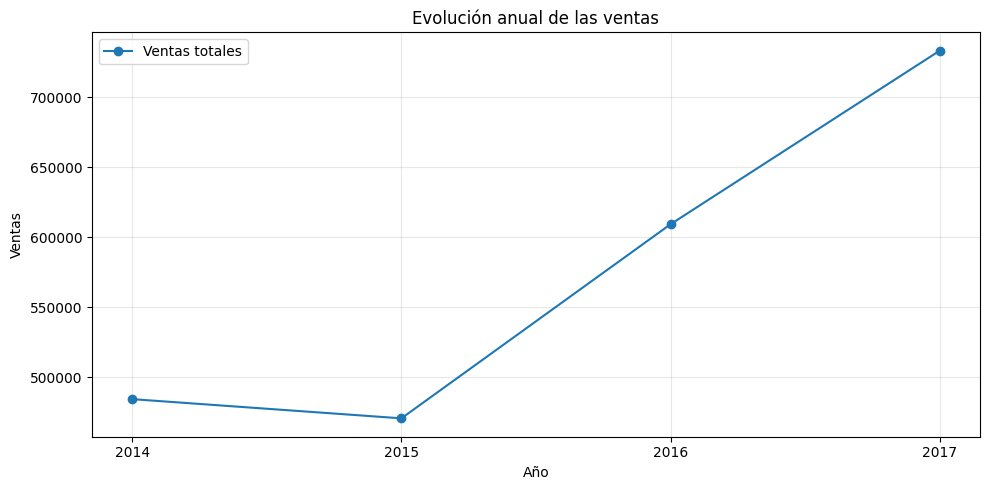

In [14]:

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    ventas_anuales["Year"],
    ventas_anuales["Ventas_Totales"],
    marker="o",
    label="Ventas totales"
)

ax.set_title("Evolución anual de las ventas")
ax.set_xlabel("Año")
ax.set_ylabel("Ventas")
ax.set_xticks(ventas_anuales["Year"])
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


### 5.2 Interpretación de la evolución anual

El análisis visual de las ventas totales muestra los siguientes patrones:

- En 2015 se observa un ligero descenso respecto a 2014.
- A partir de 2016, las ventas presentan un crecimiento notable.
- En 2017 se registra el mayor volumen de ventas del periodo analizado.

Estos resultados sugieren una evolución comercial positiva en los últimos años del conjunto de datos. No obstante, es necesario comprobar si todos los años tienen la misma cobertura temporal antes de comparar sus resultados directamente.

En el siguiente paso revisaremos las fechas disponibles y analizaremos la evolución de los beneficios para complementar el análisis de ventas.


In [15]:
print("Primera fecha de pedido:", df["Order Date"].min())
print("Última fecha de pedido:", df["Order Date"].max())

print("\nNúmero de registros por año:")
display(df.groupby("Year").size().to_frame(name="Número de registros"))

Primera fecha de pedido: 2014-01-03 00:00:00
Última fecha de pedido: 2017-12-30 00:00:00

Número de registros por año:


,Número de registros
Year,
2014,1993
2015,2102
2016,2587
2017,3312


In [16]:
print("Primera fecha de pedido:", df["Order Date"].min())
print("Última fecha de pedido:", df["Order Date"].max())

print("\nPrimer y último pedido de cada año:")
periodos = df.groupby("Year")["Order Date"].agg(
    Primera_fecha="min",
    Ultima_fecha="max"
)
display(periodos)

Primera fecha de pedido: 2014-01-03 00:00:00
Última fecha de pedido: 2017-12-30 00:00:00

Primer y último pedido de cada año:


,Primera_fecha,Ultima_fecha
Year,,
2014,2014-01-03,2014-12-31
2015,2015-01-02,2015-12-31
2016,2016-01-02,2016-12-31
2017,2017-01-01,2017-12-30


### 5.3 Evolución anual de los beneficios

Además de estudiar las ventas, es importante analizar los beneficios obtenidos por la empresa. Un aumento de las ventas no siempre implica una mejora equivalente de la rentabilidad, ya que los descuentos y los costes pueden afectar al resultado.

En esta sección compararemos las ventas totales y los beneficios anuales para evaluar cómo ha evolucionado la rentabilidad del negocio.

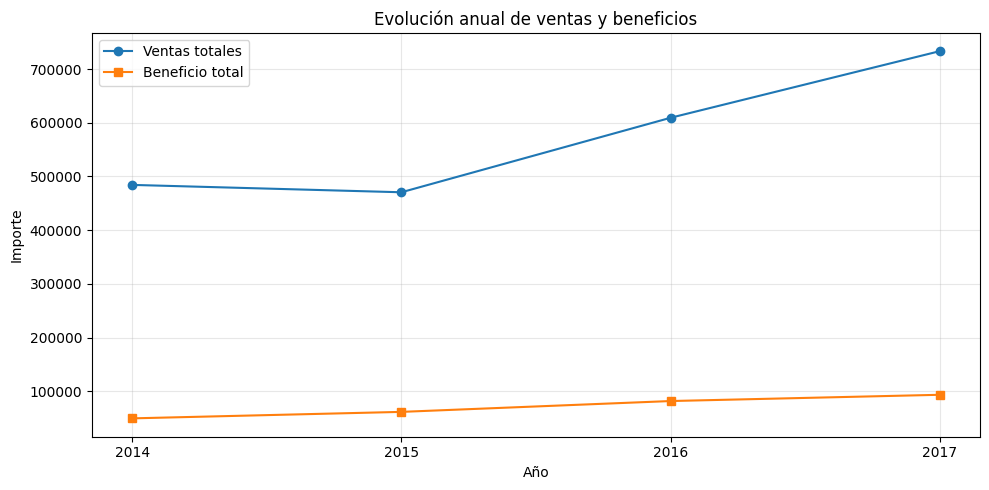

,Year,Ventas_Totales,Beneficio_Total,Margen_Beneficio_%
0,2014,484247.50,49543.97,10.23
1,2015,470532.51,61618.60,13.10
2,2016,609205.60,81795.17,13.43
3,2017,733215.26,93439.27,12.74


In [17]:
# Comparar ventas y beneficios por año
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    ventas_anuales["Year"],
    ventas_anuales["Ventas_Totales"],
    marker="o",
    label="Ventas totales"
)

ax.plot(
    ventas_anuales["Year"],
    ventas_anuales["Beneficio_Total"],
    marker="s",
    label="Beneficio total"
)

ax.set_title("Evolución anual de ventas y beneficios")
ax.set_xlabel("Año")
ax.set_ylabel("Importe")
ax.set_xticks(ventas_anuales["Year"])
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

# Mostrar los indicadores de rentabilidad
display(
    ventas_anuales[
        ["Year", "Ventas_Totales", "Beneficio_Total", "Margen_Beneficio_%"]
    ].round(2)
)

### 5.4 Hallazgos de ventas y rentabilidad

El análisis anual permite identificar tres patrones principales:

- **Crecimiento comercial:** las ventas alcanzan su valor máximo en 2017, con un total de 733.215,26.
- **Mejora del beneficio absoluto:** el beneficio aumenta desde 49.543,97 en 2014 hasta 93.439,27 en 2017.
- **Variación del margen:** el margen de beneficio alcanza su máximo en 2016, con un 13,43 %, y disminuye al 12,74 % en 2017.

Los resultados muestran que el crecimiento de las ventas y del beneficio total no implica necesariamente una mejora continua del margen. Por ello, será importante analizar qué categorías, productos y descuentos contribuyen a la rentabilidad del negocio.

Estas observaciones son descriptivas y no permiten atribuir las variaciones a una causa concreta sin realizar análisis adicionales.

### 5.5 Ventas y beneficios por categoría

En esta sección compararemos las ventas y los beneficios de las distintas categorías de productos. El objetivo es identificar cuáles tienen mayor volumen comercial y cuáles contribuyen más a la rentabilidad de la empresa.

In [18]:
# Resumir ventas, beneficios y unidades por categoría
rentabilidad_categoria = (
    df.groupby("Category")
    .agg(
        Ventas_Totales=("Sales", "sum"),
        Beneficio_Total=("Profit", "sum"),
        Unidades_Vendidas=("Quantity", "sum")
    )
    .reset_index()
)

# Calcular el margen de beneficio por categoría
rentabilidad_categoria["Margen_Beneficio_%"] = (
    rentabilidad_categoria["Beneficio_Total"]
    / rentabilidad_categoria["Ventas_Totales"] * 100
).round(2)

# Ordenar las categorías por ventas
rentabilidad_categoria = rentabilidad_categoria.sort_values(
    "Ventas_Totales", ascending=False
)

display(rentabilidad_categoria.round(2))

,Category,Ventas_Totales,Beneficio_Total,Unidades_Vendidas,Margen_Beneficio_%
2,Technology,836154.03,145454.95,6939,17.40
0,Furniture,741999.80,18451.27,8028,2.49
1,Office Supplies,719047.03,122490.80,22906,17.04


### 5.6 Hallazgos por categoría de producto

La comparación entre categorías muestra diferencias importantes en el desempeño comercial:

- **Technology** registra las mayores ventas y el mayor beneficio total, con un margen del 17,40 %.
- **Office Supplies** presenta el mayor número de unidades vendidas y un margen del 17,04 %.
- **Furniture** obtiene un margen del 2,49 %, considerablemente inferior al de las otras categorías.

Estos resultados sugieren que Furniture requiere un análisis más detallado para identificar qué productos o condiciones comerciales podrían estar asociados con su menor rentabilidad.

El análisis por categoría permite observar que el volumen de ventas, por sí solo, no es suficiente para evaluar el desempeño de un área del negocio.

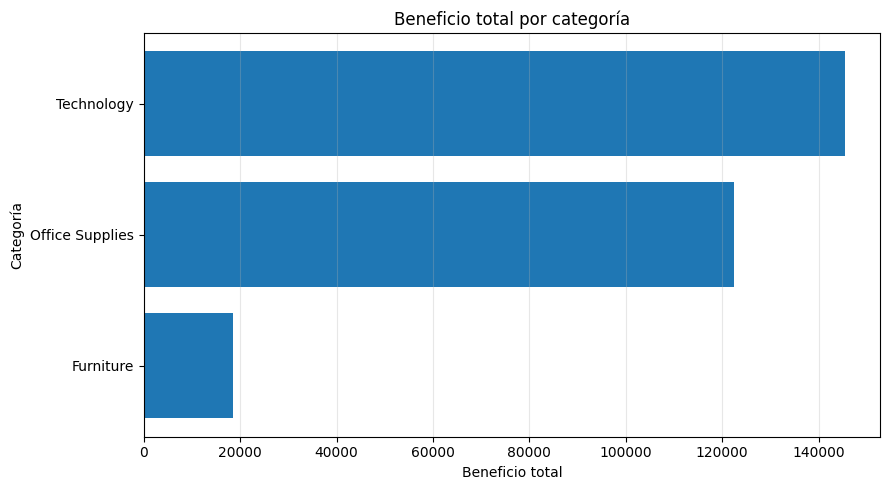

In [19]:
# Comparar el beneficio total por categoría
datos_grafico = rentabilidad_categoria.sort_values(
    "Beneficio_Total", ascending=True
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(
    datos_grafico["Category"],
    datos_grafico["Beneficio_Total"]
)

ax.set_title("Beneficio total por categoría")
ax.set_xlabel("Beneficio total")
ax.set_ylabel("Categoría")

ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 5.7 Análisis de rentabilidad por subcategoría

Las categorías agrupan productos con características diferentes. Por ello, analizaremos las subcategorías para identificar cuáles generan mayores beneficios y cuáles presentan resultados negativos.

Este análisis permitirá localizar áreas concretas que merecen una revisión comercial más detallada.

In [20]:
# Resumir los resultados por subcategoría
rentabilidad_subcategoria = (
    df.groupby(["Category", "Sub-Category"])
    .agg(
        Ventas_Totales=("Sales", "sum"),
        Beneficio_Total=("Profit", "sum"),
        Unidades_Vendidas=("Quantity", "sum")
    )
    .reset_index()
)

# Calcular el margen de beneficio
rentabilidad_subcategoria["Margen_Beneficio_%"] = (
    rentabilidad_subcategoria["Beneficio_Total"]
    / rentabilidad_subcategoria["Ventas_Totales"] * 100
).round(2)

# Ordenar desde el menor hasta el mayor beneficio
rentabilidad_subcategoria = rentabilidad_subcategoria.sort_values(
    "Beneficio_Total", ascending=True
)

display(rentabilidad_subcategoria.round(2))

,Category,Sub-Category,Ventas_Totales,Beneficio_Total,Unidades_Vendidas,Margen_Beneficio_%
3,Furniture,Tables,206965.53,-17725.48,1241,-8.56
0,Furniture,Bookcases,114880.00,-3472.56,868,-3.02
12,Office Supplies,Supplies,46673.54,-1189.10,647,-2.55
8,Office Supplies,Fasteners,3024.28,949.52,914,31.40
15,Technology,Machines,189238.63,3384.76,440,1.79
9,Office Supplies,Labels,12486.31,5546.25,1400,44.42
5,Office Supplies,Art,27118.79,6527.79,3000,24.07
7,Office Supplies,Envelopes,16476.40,6964.18,906,42.27
2,Furniture,Furnishings,91705.16,13059.14,3563,14.24
4,Office Supplies,Appliances,107532.16,18138.01,1729,16.87


### 5.8 Hallazgos por subcategoría

El análisis de rentabilidad por subcategoría permite identificar diferencias importantes:

- **Tables** presenta la mayor pérdida, con un beneficio de -17.725,48 y un margen del -8,56 %.
- **Bookcases** y **Supplies** también registran beneficios negativos.
- **Copiers** obtiene el mayor beneficio total, con 55.617,82.
- **Paper** presenta el mayor margen de beneficio, con un 43,39 %.
- **Machines** tiene un margen reducido del 1,79 %, a pesar de registrar ventas de 189.238,63.

Estos resultados identifican áreas prioritarias para investigar. En particular, conviene estudiar las subcategorías con pérdidas y comprobar si los descuentos están relacionados con una menor rentabilidad.

Los datos muestran asociaciones y resultados financieros, pero no demuestran por sí solos las causas de las pérdidas.

### 5.9 Relación entre descuentos y beneficios

Los descuentos pueden ayudar a impulsar las ventas, pero también pueden reducir la rentabilidad. En esta sección estudiaremos la relación entre el porcentaje de descuento aplicado y el beneficio obtenido en cada registro.

El objetivo es comprobar si los descuentos más elevados tienden a coincidir con beneficios más bajos o con pérdidas.

In [21]:
# Resumir los resultados según el descuento aplicado
analisis_descuentos = (
    df.groupby("Discount")
    .agg(
        Registros=("Profit", "size"),
        Ventas_Totales=("Sales", "sum"),
        Beneficio_Total=("Profit", "sum"),
        Beneficio_Promedio=("Profit", "mean")
    )
    .reset_index()
    .sort_values("Discount")
)

display(analisis_descuentos.round(2))

,Discount,Registros,Ventas_Totales,Beneficio_Total,Beneficio_Promedio
0,0.00,4798,1087908.47,320987.60,66.90
1,0.10,94,54369.35,9029.18,96.06
2,0.15,52,27558.52,1418.99,27.29
3,0.20,3657,764594.37,90337.31,24.70
4,0.30,227,103226.66,-10369.28,-45.68
5,0.32,27,14493.46,-2391.14,-88.56
6,0.40,206,116417.78,-23057.05,-111.93
7,0.45,11,5484.97,-2493.11,-226.65
8,0.50,66,58918.54,-20506.43,-310.70
9,0.60,138,6644.70,-5944.66,-43.08


### 5.10 Hallazgos sobre descuentos y rentabilidad

El análisis de los registros agrupados por descuento muestra una asociación entre los descuentos elevados y los resultados negativos de rentabilidad.

- Los descuentos del 0 %, 10 %, 15 % y 20 % presentan beneficios promedio positivos.
- A partir del 30 % de descuento, todos los niveles observados presentan beneficios promedio negativos.
- Los descuentos del 70 % y 80 % registran beneficios promedio de -95,87 y -101,80, respectivamente.

Estos resultados sugieren que los descuentos elevados merecen una revisión comercial, ya que pueden estar relacionados con una menor rentabilidad.

No obstante, el análisis es descriptivo y no demuestra causalidad. Para profundizar, será necesario comparar los descuentos y beneficios dentro de cada categoría o subcategoría de productos.

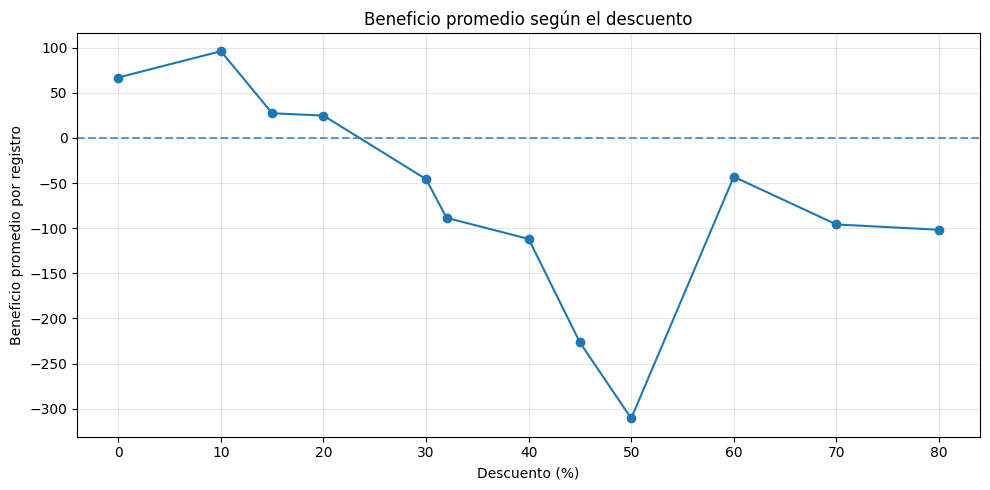

In [22]:
# Visualizar el beneficio promedio por nivel de descuento
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    analisis_descuentos["Discount"] * 100,
    analisis_descuentos["Beneficio_Promedio"],
    marker="o"
)

ax.axhline(0, linestyle="--", alpha=0.7)

ax.set_title("Beneficio promedio según el descuento")
ax.set_xlabel("Descuento (%)")
ax.set_ylabel("Beneficio promedio por registro")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 5.11 Interpretación del gráfico de descuentos

El gráfico muestra una relación generalmente negativa entre el nivel de descuento y el beneficio promedio por registro.

- Los descuentos del 0 % al 20 % presentan beneficios promedio positivos.
- A partir del 30 %, los beneficios promedio son negativos en los niveles observados.
- El descuento del 50 % registra el beneficio promedio más bajo.
- En el nivel del 60 % se observa una recuperación del beneficio promedio, aunque este continúa siendo negativo.

La tendencia sugiere que los descuentos elevados están asociados con una menor rentabilidad. Sin embargo, las variaciones entre niveles indican que también pueden influir los productos y las categorías a los que se aplican los descuentos.

Por tanto, estos resultados deben interpretarse como una asociación descriptiva y no como una prueba de causalidad.

### 5.12 Descuentos y rentabilidad por categoría

Para profundizar en la relación entre descuentos y beneficios, compararemos el beneficio promedio de cada categoría según el nivel de descuento aplicado.

Este análisis permitirá comprobar si las categorías presentan patrones diferentes y ayudará a identificar dónde conviene investigar con mayor detalle las pérdidas asociadas a los descuentos.

In [23]:
# Comparar el beneficio promedio por categoría y descuento
descuento_categoria = (
    df.groupby(["Category", "Discount"])
    .agg(
        Registros=("Profit", "size"),
        Beneficio_Promedio=("Profit", "mean"),
        Beneficio_Total=("Profit", "sum")
    )
    .reset_index()
)

# Mostrar los resultados
display(descuento_categoria.round(2))

,Category,Discount,Registros,Beneficio_Promedio,Beneficio_Total
0,Furniture,0.00,836,69.54,58133.08
1,Furniture,0.10,76,93.57,7111.01
2,Furniture,0.15,52,27.29,1418.99
3,Furniture,0.20,615,10.19,6265.95
4,Furniture,0.30,222,-48.18,-10695.32
5,Furniture,0.32,27,-88.56,-2391.14
6,Furniture,0.40,75,-215.83,-16187.40
7,Furniture,0.45,11,-226.65,-2493.11
8,Furniture,0.50,54,-238.36,-12871.20
9,Furniture,0.60,138,-43.08,-5944.66


### 5.13 Hallazgos sobre descuentos por categoría

El análisis por categoría muestra que la relación entre descuentos y rentabilidad presenta patrones diferentes:

- **Furniture:** los descuentos del 30 % o superiores presentan beneficios promedio negativos en todos los niveles observados.
- **Office Supplies:** los descuentos del 70 % y 80 % se asocian con beneficios promedio negativos.
- **Technology:** los descuentos del 40 %, 50 % y 70 % presentan beneficios promedio negativos.

Estos resultados refuerzan la importancia de estudiar los descuentos teniendo en cuenta la categoría del producto. También es necesario considerar el número de registros de cada grupo, ya que algunos niveles de descuento tienen pocas observaciones.

El análisis identifica asociaciones entre descuentos y beneficios, pero no demuestra por sí solo que los descuentos sean la causa de las pérdidas.

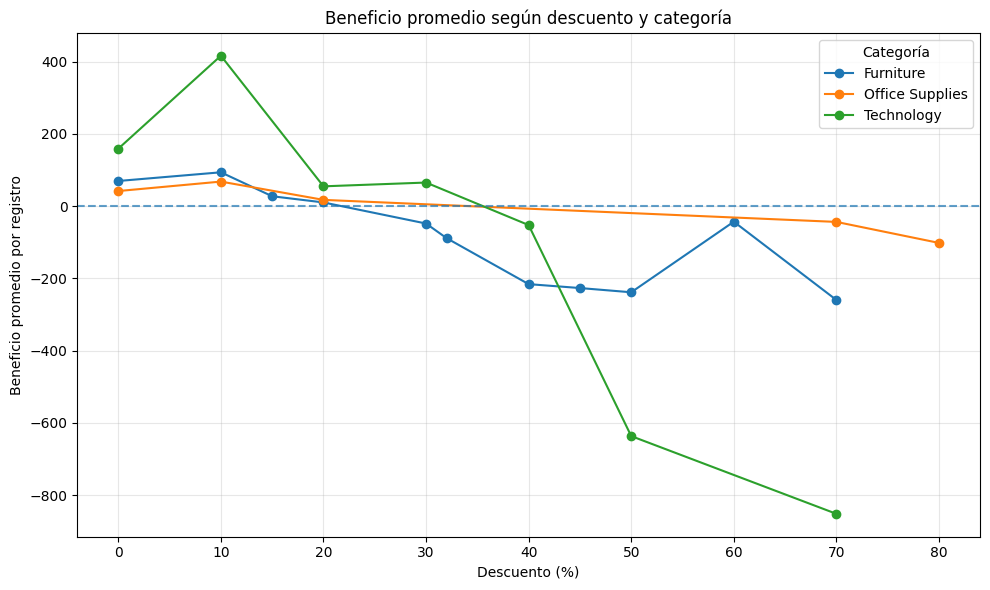

In [24]:
# Comparar el beneficio promedio por categoría y descuento
fig, ax = plt.subplots(figsize=(10, 6))

for categoria in descuento_categoria["Category"].unique():
    datos = descuento_categoria[
        descuento_categoria["Category"] == categoria
    ].sort_values("Discount")

    ax.plot(
        datos["Discount"] * 100,
        datos["Beneficio_Promedio"],
        marker="o",
        label=categoria
    )

ax.axhline(0, linestyle="--", alpha=0.7)
ax.set_title("Beneficio promedio según descuento y categoría")
ax.set_xlabel("Descuento (%)")
ax.set_ylabel("Beneficio promedio por registro")
ax.legend(title="Categoría")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 5.14 Interpretación del análisis por categoría y descuento

El gráfico permite comparar el beneficio promedio por registro según la categoría y el nivel de descuento aplicado.

- **Furniture** muestra beneficios promedio negativos a partir del 30 % de descuento en los niveles observados.
- **Office Supplies** presenta beneficios promedio negativos con descuentos del 70 % y 80 %.
- **Technology** registra beneficios promedio negativos con descuentos del 40 %, 50 % y 70 %.

En general, los resultados muestran una asociación entre descuentos elevados y una menor rentabilidad. Sin embargo, existen diferencias entre categorías y algunos niveles cuentan con pocas observaciones, por lo que deben interpretarse con cautela.

Como siguiente paso, se analizarán los productos con mayores pérdidas para identificar cuáles contribuyen más a los resultados negativos.

### 5.15 Productos con mayores pérdidas

En esta sección identificaremos los productos que acumulan las mayores pérdidas económicas. El objetivo es detectar casos concretos que merecen una revisión comercial y complementar los hallazgos obtenidos en el análisis por categoría y descuento.

In [25]:
# Agrupar las ventas y los beneficios por producto
rentabilidad_producto = (
    df.groupby(["Product ID", "Product Name", "Category", "Sub-Category"])
    .agg(
        Ventas_Totales=("Sales", "sum"),
        Beneficio_Total=("Profit", "sum"),
        Unidades_Vendidas=("Quantity", "sum")
    )
    .reset_index()
)

# Seleccionar los 10 productos con mayores pérdidas
productos_mayores_perdidas = (
    rentabilidad_producto
    .sort_values("Beneficio_Total", ascending=True)
    .head(10)
)

display(productos_mayores_perdidas.round(2))

,Product ID,Product Name,Category,Sub-Category,Ventas_Totales,Beneficio_Total,Unidades_Vendidas
1645,TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,Technology,Machines,11099.96,-8879.97,9
1650,TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,Technology,Machines,16829.90,-4589.97,18
1696,TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,Technology,Machines,7999.98,-3839.99,4
326,FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Furniture,Tables,9917.64,-2876.12,27
344,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,Furniture,Tables,9544.72,-1934.40,33
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,Office Supplies,Binders,17965.07,-1878.17,27
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,Technology,Machines,22638.48,-1811.08,6
1465,OFF-SU-10002881,Martin Yale Chadless Opener Electric Letter Op...,Office Supplies,Supplies,16656.20,-1299.18,22
346,FUR-TA-10001950,Balt Solid Wood Round Tables,Furniture,Tables,6518.75,-1201.06,19
375,FUR-TA-10004289,BoxOffice By Design Rectangular and Half-Moon ...,Furniture,Tables,1706.25,-1148.44,15


### 5.16 Hallazgos sobre los productos con mayores pérdidas

El análisis de los diez productos con menor beneficio acumulado permite identificar los siguientes patrones:

- La impresora 3D Cubify CubeX Double Head Print presenta la mayor pérdida acumulada, con -8.879,97.
- La impresora Lexmark MX611dhe registra una pérdida de -4.589,97.
- Varios modelos de mesas de la categoría Furniture aparecen entre los productos con mayores pérdidas.
- También se identifican productos de Office Supplies con beneficios acumulados negativos.

Los resultados muestran que las pérdidas se concentran en determinados productos y no exclusivamente en una categoría. Por ello, conviene investigar el efecto de los descuentos y las condiciones comerciales sobre estos artículos antes de proponer medidas correctivas.

### 5.17 Descuentos aplicados a los productos con mayores pérdidas

En esta sección analizaremos los descuentos aplicados a los productos con mayores pérdidas acumuladas. El objetivo es comprobar si estos artículos presentan descuentos elevados y comparar el beneficio promedio observado en sus operaciones.

In [26]:
# Identificar los productos con mayores pérdidas
ids_productos_perdida = productos_mayores_perdidas["Product ID"]

# Filtrar los registros correspondientes a esos productos
df_productos_perdida = df[
    df["Product ID"].isin(ids_productos_perdida)
].copy()

# Resumir resultados por producto y descuento
analisis_productos_descuento = (
    df_productos_perdida
    .groupby(["Product Name", "Discount"])
    .agg(
        Registros=("Profit", "size"),
        Ventas_Totales=("Sales", "sum"),
        Beneficio_Total=("Profit", "sum"),
        Beneficio_Promedio=("Profit", "mean")
    )
    .reset_index()
    .sort_values(["Product Name", "Discount"])
)

display(analisis_productos_descuento.round(2))

,Product Name,Discount,Registros,Ventas_Totales,Beneficio_Total,Beneficio_Promedio
0,Balt Solid Wood Round Tables,0.00,2,3571.92,321.47,160.74
1,Balt Solid Wood Round Tables,0.40,2,2946.83,-1522.53,-761.27
2,BoxOffice By Design Rectangular and Half-Moon ...,0.45,1,721.88,-420.00,-420.00
3,BoxOffice By Design Rectangular and Half-Moon ...,0.50,2,984.38,-728.44,-364.22
4,Bush Advantage Collection Racetrack Conference...,0.00,1,3393.68,610.86,610.86
5,Bush Advantage Collection Racetrack Conference...,0.30,1,890.84,-152.72,-152.72
6,Bush Advantage Collection Racetrack Conference...,0.40,3,3054.31,-1119.91,-373.30
7,Bush Advantage Collection Racetrack Conference...,0.45,1,933.26,-458.15,-458.15
8,Bush Advantage Collection Racetrack Conference...,0.50,1,1272.63,-814.48,-814.48
9,Chromcraft Bull-Nose Wood Oval Conference Tabl...,0.00,1,1652.94,231.41,231.41


### 5.18 Hallazgos sobre descuentos en productos con pérdidas

El análisis de los productos con mayores pérdidas acumuladas muestra varios patrones relevantes:

- La impresora Cubify CubeX Double Head Print registra un beneficio positivo de 360,00 con un descuento del 20 %, mientras que sus dos registros con un descuento del 70 % acumulan pérdidas de 9.239,97.
- Varios modelos de mesas presentan beneficios positivos en operaciones sin descuento y pérdidas en operaciones con descuentos elevados.
- El sistema GBC DocuBind P400 muestra beneficios positivos con descuentos del 0 % y 20 %, y pérdidas con descuentos del 70 % y 80 %.

Estos resultados sugieren que los descuentos elevados pueden estar relacionados con las pérdidas de determinados productos. No obstante, las diferencias en las condiciones de cada operación y el reducido número de observaciones de algunos grupos impiden atribuir las pérdidas exclusivamente al descuento.

Los resultados identifican productos que merecen una revisión comercial más detallada.

### 5.19 Impacto de los productos con mayores pérdidas

En esta sección compararemos las pérdidas acumuladas de los diez productos identificados con el beneficio total del conjunto de datos. Esto permitirá dimensionar su impacto económico y valorar la importancia de revisar estos artículos.

In [27]:
# Beneficio total de todos los registros
beneficio_global = df["Profit"].sum()

# Beneficio acumulado de los 10 productos con mayores pérdidas
beneficio_top_perdidas = productos_mayores_perdidas["Beneficio_Total"].sum()

# Calcular la magnitud de las pérdidas frente al beneficio global
porcentaje_impacto = (
    abs(beneficio_top_perdidas) / beneficio_global * 100
)

print(f"Beneficio global: {beneficio_global:,.2f}")
print(f"Beneficio acumulado de los 10 productos: {beneficio_top_perdidas:,.2f}")
print(f"Magnitud de esas pérdidas respecto al beneficio global: {porcentaje_impacto:.2f}%")

Beneficio global: 286,397.02
Beneficio acumulado de los 10 productos: -29,458.37
Magnitud de esas pérdidas respecto al beneficio global: 10.29%


### 5.20 Impacto de los productos con mayores pérdidas

El beneficio global del conjunto de datos asciende a 286.397,02. Por su parte, los diez productos con mayores pérdidas acumulan un beneficio de -29.458,37.

La magnitud de estas pérdidas equivale al 10,29 % del beneficio global observado.

Este resultado muestra que un grupo reducido de productos presenta pérdidas acumuladas económicamente relevantes. Por ello, estos artículos constituyen candidatos prioritarios para revisar sus precios, descuentos y condiciones comerciales.

La comparación es descriptiva y no implica que eliminar estos productos o modificar sus descuentos aumentaría automáticamente el beneficio en esa misma proporción.

## 6. Conclusiones y recomendaciones

### 6.1 Conclusiones principales

El análisis del conjunto de datos de ventas permitió identificar los siguientes resultados:

1. **Evolución comercial:** las ventas aumentaron notablemente entre 2015 y 2017, alcanzando su máximo en 2017.
2. **Rentabilidad anual:** el beneficio total creció durante el periodo analizado, aunque el margen de beneficio disminuyó del 13,43 % en 2016 al 12,74 % en 2017.
3. **Diferencias entre categorías:** Technology obtuvo el mayor beneficio total, mientras que Furniture presentó un margen de beneficio considerablemente inferior.
4. **Subcategorías con pérdidas:** Tables, Bookcases y Supplies registraron beneficios acumulados negativos.
5. **Descuentos y beneficios:** los descuentos elevados aparecieron asociados con beneficios promedio negativos en varios grupos de productos y categorías.
6. **Productos prioritarios:** los diez productos con mayores pérdidas acumularon un resultado de -29.458,37, cuya magnitud equivale al 10,29 % del beneficio global.

### 6.2 Recomendaciones comerciales

A partir de los resultados, se proponen las siguientes acciones:

- Revisar los descuentos aplicados a los productos con pérdidas recurrentes.
- Analizar los costes, precios y condiciones comerciales de la subcategoría Tables.
- Investigar por qué Furniture presenta un margen de beneficio reducido.
- Evaluar la rentabilidad por producto antes de establecer promociones.
- Realizar un seguimiento periódico de las ventas, los beneficios y los márgenes.
- Profundizar en el análisis de descuentos por producto y categoría para distinguir patrones generales de casos particulares.

### 6.3 Limitaciones del análisis

Este proyecto utiliza un análisis descriptivo de los datos disponibles. Los resultados permiten identificar patrones y asociaciones, pero no demuestran causalidad.

Además, algunos grupos de descuento contienen pocas observaciones, por lo que sus promedios deben interpretarse con precaución. Para confirmar las causas de las pérdidas sería necesario estudiar información adicional sobre costes, precios y condiciones comerciales.

### 6.4 Conclusión final

El análisis muestra que aumentar las ventas no garantiza maximizar la rentabilidad. La categoría del producto, el margen obtenido y las condiciones comerciales deben evaluarse conjuntamente.

El proyecto permitió identificar áreas de oportunidad, especialmente en Furniture, en algunas subcategorías con pérdidas y en determinados productos sometidos a descuentos elevados. Estos hallazgos pueden servir como punto de partida para investigaciones más detalladas y decisiones comerciales basadas en datos.